# Citation prediction on a scholarly knowledge graph

**Task.** Given a small knowledge graph of research papers (abstracts, authors, known citations), predict for pairs of papers `(u, v)`
whether `u` cites `v`. This is a binary classification problem scored with **log loss**; the pairs to predict are citations that were
*hidden* from the graph.

**What this notebook does**

1. It models the data as a knowledge graph: `Author --wrote--> Paper --cites--> Paper`, plus the abstract of every paper (section 1).
2. It checks how the test set was built and builds the training set to match (section 2).
3. It fixes a bug in how training features were computed: features of a known edge were computed on a graph that still contained
   that edge, which leaks the answer. The *edge-out-of-fold* construction removes it (sections 3-4).
4. It adds features: PageRank, two-hop paths, TF-IDF, graph-aware SBERT embeddings, SVD embeddings and an
   author-to-author citation prior, each verified against reference implementations in the test-suite (section 5).
5. It measures the effect of every feature group with ablations (section 6) and checks calibration and errors (section 7).

**Runs anywhere.** Without real data it runs on a small synthetic citation network (`citepred.synthetic`). To run on the
challenge data, set the environment variable `CITEPRED_DATA` to the folder that contains `edgelist.txt`, `abstracts.txt`,
`authors.txt` and `test.txt` (on Kaggle it is found automatically). The real-data numbers in the documentation come from
`scripts/run_real.py`.


In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    import citepred
except ImportError:                       # e.g. on Kaggle: install the package from GitHub first
    %pip install -q git+https://github.com/vagelistemp/NLP-Citation-Prediction-Project.git
    import citepred

from citepred.io import load_dataset, write_submission
from citepred.synthetic import make_synthetic
from citepred.features import FEATURE_GROUPS, DEFAULT_GROUPS, ORIGINAL_9, FeatureBuilder, groups_for, names_for
from citepred.protocol import build_training_set, default_hidden_fraction
from citepred.pipeline import pseudo_test_split, evaluate_subset, summarise
from citepred.model import calibration_table

SEED = 0
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
CANDIDATES = [os.environ.get("CITEPRED_DATA"), "/kaggle/input/nlp-cse-uoi-2025/data_new", "data"]
DATA_DIR = next((Path(p) for p in CANDIDATES if p and (Path(p) / "edgelist.txt").exists()), None)
print("data directory:", DATA_DIR if DATA_DIR else "none found -> using the synthetic network")

data directory: none found -> using the synthetic network


## 1. Data
Papers are numbered `0 .. n-1`. `edges` lists known citations `(citing, cited)`. `test_pairs` are the pairs to predict.

In [2]:
if DATA_DIR:
    ds = load_dataset(DATA_DIR)
else:
    ds = make_synthetic(2500, seed=SEED)
n, m = ds.n_papers, len(ds.edges)
summary = pd.Series({
    "dataset": ds.name, "papers": n, "known citations": m, "test pairs": len(ds.test_pairs),
    "citations per paper (mean)": round(m / n, 2),
    "authors per paper (mean)": round(np.mean([len(a) for a in ds.authors]), 2),
    "abstract length, words (mean)": round(np.mean([len(t.split()) for t in ds.abstracts]), 1),
})
summary.to_frame("value")

,value
dataset,synthetic-2500
papers,2500
known citations,16363
test pairs,2088
citations per paper (mean),6.55
authors per paper (mean),2.51
"abstract length, words (mean)",64.8


**The knowledge graph.** Papers and authors are the nodes; `cites` and `wrote` are the edges; each paper carries its abstract.
`citepred.kg` makes it explicit. Every feature below is a question asked of this graph.

In [3]:
from citepred.kg import build_knowledge_graph
kg = build_knowledge_graph(ds)
pd.Series(kg.summary(), name='knowledge graph').round(3).to_frame()


,knowledge graph
paper_nodes,2500.000
author_nodes,320.000
cites_edges,16363.000
wrote_edges,6287.000
mean_references_per_paper,6.545
mean_citations_per_paper,6.545
papers_without_references,0.258
papers_without_authors,0.000
mean_authors_per_paper,2.515
mean_papers_per_author,19.647


## 2. How is the test set built? (checks that decide the design)
If the test pairs are *hidden* citations, then none of them can appear in the edge list, and a model must be trained on pairs that look
the same: graph features computed on a graph that does **not** contain the pair's own edge.

In [4]:
E, T = ds.edges, ds.test_pairs
known = set(map(tuple, E.tolist()))
out_deg, in_deg = np.bincount(E[:, 0], minlength=n), np.bincount(E[:, 1], minlength=n)
checks = pd.Series({
    "test pairs found in the edge list": sum(tuple(p) in known for p in T.tolist()),
    "mutual citations (u cites v and v cites u)": sum((b, a) in known for a, b in known),
    "papers that cite nothing in the data": f"{(out_deg == 0).mean():.1%}",
    "share of edges with citing id > cited id": f"{(E[:, 0] > E[:, 1]).mean():.1%}",
    "share of test pairs with first id > second id": f"{(T[:, 0] > T[:, 1]).mean():.1%}",
})
checks.to_frame("value")

,value
test pairs found in the edge list,0
mutual citations (u cites v and v cites u),0
papers that cite nothing in the data,25.8%
share of edges with citing id > cited id,48.8%
share of test pairs with first id > second id,49.6%


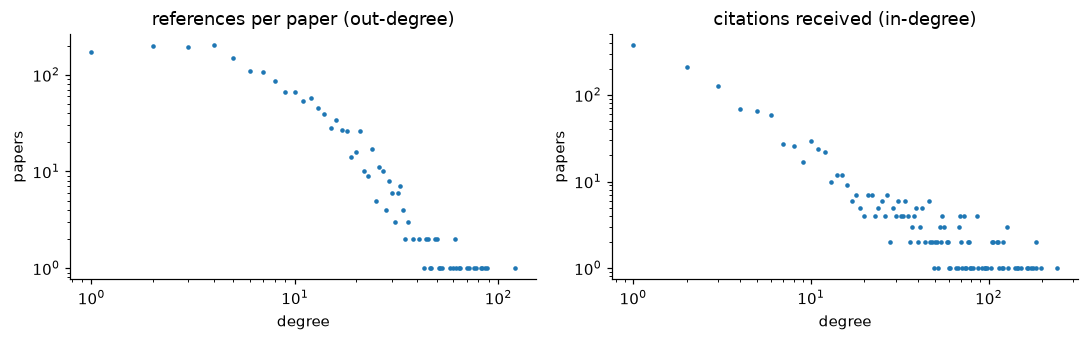

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, d, title in ((ax[0], out_deg, "references per paper (out-degree)"), (ax[1], in_deg, "citations received (in-degree)")):
    vals, counts = np.unique(d[d > 0], return_counts=True)
    a.loglog(vals, counts, ".", ms=4); a.set_title(title); a.set_xlabel("degree"); a.set_ylabel("papers")
plt.tight_layout(); plt.show()

**Reading.** On the real challenge data no test pair is in the edge list, there are no mutual citations, and the test positives are a
random ~5% of all citations: the test set is *hidden edges plus uniformly random non-edges*. The training set below is built the same way.
Because the real test labels are secret, we also create a **pseudo-test split** with the same recipe and known answers: a real held-out score.

In [6]:
dev = ds if ds.test_labels is not None else pseudo_test_split(ds)       # synthetic data already has labelled hidden pairs
print(f"{len(dev.test_pairs)} labelled test pairs, graph for training has {len(dev.edges)} known edges "
      f"({len(dev.test_pairs) // 2} edges are hidden); positive rate {dev.test_labels.mean():.2f}")

2088 labelled test pairs, graph for training has 16363 known edges (1044 edges are hidden); positive rate 0.50


## 3. The leak: why graph features must not see the pair's own edge
A positive training pair is a known edge `(u, v)`. If the graph contains it, `out_degree(u) >= 1` **because of that edge**, while a random
negative pair often has `out_degree(u) = 0`. A model learns "has a reference => citation", which is useless when the positives are
*hidden* edges. We measure this directly.

In [7]:
from citepred.protocol import make_pairs
pairs, y, fold = make_pairs(dev, n_folds=5, hidden_fraction=default_hidden_fraction(dev), seed=SEED)
b = FeatureBuilder(dev, None, svd_dim=16)
leaky = build_training_set(dev, b, ["degree"], n_folds=5, seed=SEED, leak=True, log=lambda *a: None)
clean = build_training_set(dev, b, ["degree"], n_folds=5, seed=SEED, leak=False, log=lambda *a: None)
rows = []
for name, ts in (("leaky (full graph, as in the first notebook)", leaky), ("leak-free (edge-out-of-fold)", clean)):
    pos, neg = ts.y == 1, ts.y == 0
    rows.append({"protocol": name,
                 "positives with out-degree(u) >= 1": f"{(ts.X.out_degree_p1[pos] >= 1).mean():.1%}",
                 "negatives with out-degree(u) >= 1": f"{(ts.X.out_degree_p1[neg] >= 1).mean():.1%}",
                 "mean out-degree(u), positives": round(ts.X.out_degree_p1[pos].mean(), 1),
                 "mean out-degree(u), negatives": round(ts.X.out_degree_p1[neg].mean(), 1)})
Tt = dev.test_pairs; yt = dev.test_labels
od = np.bincount(dev.edges[:, 0], minlength=n)
rows.append({"protocol": "the real test pairs (hidden edges removed from the graph)",
             "positives with out-degree(u) >= 1": f"{(od[Tt[yt == 1, 0]] >= 1).mean():.1%}",
             "negatives with out-degree(u) >= 1": f"{(od[Tt[yt == 0, 0]] >= 1).mean():.1%}",
             "mean out-degree(u), positives": round(od[Tt[yt == 1, 0]].mean(), 1),
             "mean out-degree(u), negatives": round(od[Tt[yt == 0, 0]].mean(), 1)})
pd.DataFrame(rows).set_index("protocol")

,positives with out-degree(u) >= 1,negatives with out-degree(u) >= 1,"mean out-degree(u), positives","mean out-degree(u), negatives"
protocol,,,,
"leaky (full graph, as in the first notebook)",100.0%,73.6%,20.1,6.6
leak-free (edge-out-of-fold),98.8%,73.2%,18.0,6.2
the real test pairs (hidden edges removed from the graph),98.9%,75.7%,18.8,6.7


In the leaky training set *every* positive has a reference (100%) by construction, while on the hidden test positives some do not: the model
has learned a shortcut that the test set does not offer. In the leak-free set the training positives look like the test positives.

## 4. The leakage-free protocol (edge-out-of-fold)
Every training pair gets a fold. For fold *f* the graph is built from all known edges **except the fold-*f* positive edges**, and every
graph-dependent feature of fold-*f* pairs (positives and negatives) is computed on that graph. Each pair is therefore featurised exactly
like a hidden test pair. Each fold hides about the same share of edges as the test set does, and test pairs are featurised on the full known graph.
The graph-independent features (text similarity, shared authors) can be computed once.

The cell below compares the two protocols on the **nine baseline features**.

In [8]:
E_emb = None
if DATA_DIR and os.environ.get("CITEPRED_SBERT", "1") == "1":
    from citepred.embed import embed_abstracts
    E_emb = embed_abstracts(ds.abstracts, Path(os.environ.get("CITEPRED_CACHE", ".cache")) / "sbert", max_seq_length=128)   # resumable, slow on CPU
builder = FeatureBuilder(dev, E_emb, svd_dim=32)
g9 = groups_for(ORIGINAL_9)
X9_test = builder.build(dev.edges, dev.test_pairs, g9)
fast = dict(learning_rate=0.08, n_estimators=600)
runs = {}
for leak in (True, False):
    ts = build_training_set(dev, builder, g9, n_folds=5, seed=SEED, leak=leak, log=lambda *a: None)
    runs["leaky" if leak else "leak-free"] = evaluate_subset(ts, X9_test, dev.test_labels, ORIGINAL_9, params=fast, log=lambda *a: None)
table = summarise(runs).drop(columns="run").assign(run=list(runs)).set_index("run")
table.round(4)

,protocol,features,cv_logloss,cv_auc,test_logloss,test_auc
run,,,,,,
leaky,leaky,8,0.1943,0.9757,0.2966,0.9567
leak-free,leak-free,8,0.2370,0.9655,0.2533,0.9619


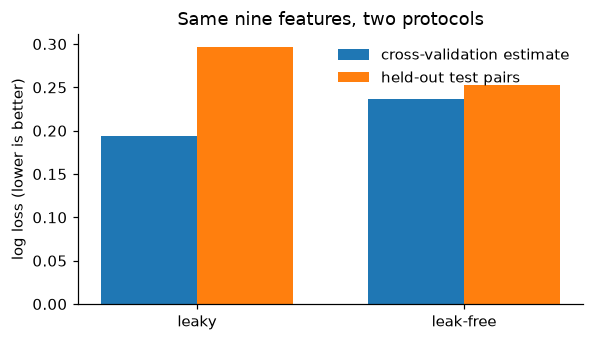

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
x = np.arange(2)
ax.bar(x - 0.18, [runs[k]["cv"]["logloss"] for k in runs], 0.36, label="cross-validation estimate")
ax.bar(x + 0.18, [runs[k]["test"]["logloss"] for k in runs], 0.36, label="held-out test pairs")
ax.set_xticks(x); ax.set_xticklabels(list(runs)); ax.set_ylabel("log loss (lower is better)"); ax.legend(frameon=False)
ax.set_title("Same nine features, two protocols"); plt.tight_layout(); plt.show()

**Reading.** With the baseline (full-graph) construction the cross-validation score looks excellent and the model is nevertheless much worse on the held-out
pairs. With the edge-out-of-fold construction the cross-validation estimate *predicts* the held-out score, so it can be trusted for model selection.
(The baseline notebook showed the same signature: out-of-fold log loss 0.112 against a Kaggle score of 0.214.)

## 5. Features
All graph quantities are computed with sparse matrices (no per-pair Python loops) and checked against `networkx` and plain set arithmetic in the tests.

In [10]:
meaning = {
    "degree": "references / citations of each paper, preferential attachment",
    "neighbors": "common references, common citers, Jaccard, common neighbours, Adamic-Adar, resource allocation",
    "paths": "two-hop citation paths u->w->v and v->w->u, reverse edge",
    "pagerank": "PageRank of both papers",
    "svd": "rank-32 SVD of the citation matrix: u-citing profile times v-cited profile",
    "emb_graph": "similarity of u to the papers that cite v; of v to the papers u cites (SBERT)",
    "authors_graph": "how often the authors of u have already cited the authors of v",
    "tfidf": "TF-IDF cosine of the abstracts",
    "sbert": "SBERT (MiniLM) cosine of the abstracts",
    "authors_static": "shared authors, author Jaccard, authors per paper",
}
pd.DataFrame([{"group": g, "features": len(FEATURE_GROUPS[g]), "what": meaning[g]} for g in DEFAULT_GROUPS]).set_index("group")

,features,what
group,,
degree,5,"references / citations of each paper, preferen..."
neighbors,8,"common references, common citers, Jaccard, com..."
paths,3,"two-hop citation paths u->w->v and v->w->u, re..."
pagerank,2,PageRank of both papers
svd,2,rank-32 SVD of the citation matrix: u-citing p...
emb_graph,2,similarity of u to the papers that cite v; of ...
authors_graph,1,how often the authors of u have already cited ...
tfidf,1,TF-IDF cosine of the abstracts
sbert,1,SBERT (MiniLM) cosine of the abstracts


## 6. Building all features once and ablating
Graph features are the slow part, so they are built once for **all** groups; every ablation is then a column selection followed by cross-validation.
Early stopping uses a different fold from the one being scored.

In [11]:
t0 = time.time()
groups = builder.available(DEFAULT_GROUPS)
all_features = names_for(groups)
ts_all = build_training_set(dev, builder, groups, n_folds=5, seed=SEED, leak=False, log=lambda *a: None)
X_test = builder.build(dev.edges, dev.test_pairs, groups)
print(f"{len(ts_all.y)} training rows x {len(all_features)} features built in {time.time() - t0:.0f}s")

9810 training rows x 26 features built in 1s


In [12]:
steps, cumulative = [("original 9 features", list(ORIGINAL_9))], list(ORIGINAL_9)
for label, gs in [("+ degree and neighbourhood measures", ["degree", "neighbors"]), ("+ two-hop paths", ["paths"]), ("+ PageRank", ["pagerank"]),
                  ("+ TF-IDF", ["tfidf"]), ("+ author citation prior", ["authors_graph"]), ("+ graph-aware embeddings", ["emb_graph"]),
                  ("+ SVD", ["svd"]), ("+ remaining author features", ["authors_static"])]:
    cumulative = cumulative + [f for g in gs for f in FEATURE_GROUPS[g] if f not in cumulative]
    steps.append((label, list(cumulative)))
rows = []
for label, feats in steps:
    feats = [f for f in feats if f in ts_all.X.columns]
    r = evaluate_subset(ts_all, X_test, dev.test_labels, feats, params=fast, log=lambda *a: None)
    rows.append({"step": label, "features": len(feats), "cv_logloss": r["cv"]["logloss"], "test_logloss": r["test"]["logloss"], "test_auc": r["test"]["auc"]})
ablation = pd.DataFrame(rows).set_index("step")
ablation.round(4)

,features,cv_logloss,test_logloss,test_auc
step,,,,
original 9 features,8,0.2370,0.2533,0.9619
+ degree and neighbourhood measures,14,0.2267,0.2379,0.9667
+ two-hop paths,17,0.2263,0.2369,0.9670
+ PageRank,19,0.2265,0.2356,0.9672
+ TF-IDF,20,0.1885,0.1956,0.9774
+ author citation prior,21,0.1863,0.1965,0.9770
+ graph-aware embeddings,21,0.1863,0.1965,0.9770
+ SVD,23,0.1881,0.1959,0.9771
+ remaining author features,26,0.1860,0.1970,0.9769


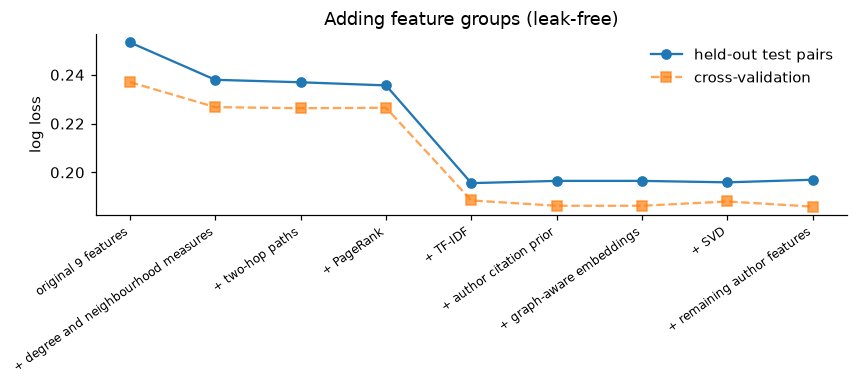

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(len(ablation)), ablation.test_logloss, "o-", label="held-out test pairs")
ax.plot(range(len(ablation)), ablation.cv_logloss, "s--", label="cross-validation", alpha=0.7)
ax.set_xticks(range(len(ablation))); ax.set_xticklabels(ablation.index, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("log loss"); ax.legend(frameon=False); ax.set_title("Adding feature groups (leak-free)"); plt.tight_layout(); plt.show()

## 7. The final model: importance, calibration and errors

{'logloss': 0.1962, 'auc': 0.9772, 'brier': 0.0586, 'accuracy': 0.9171}


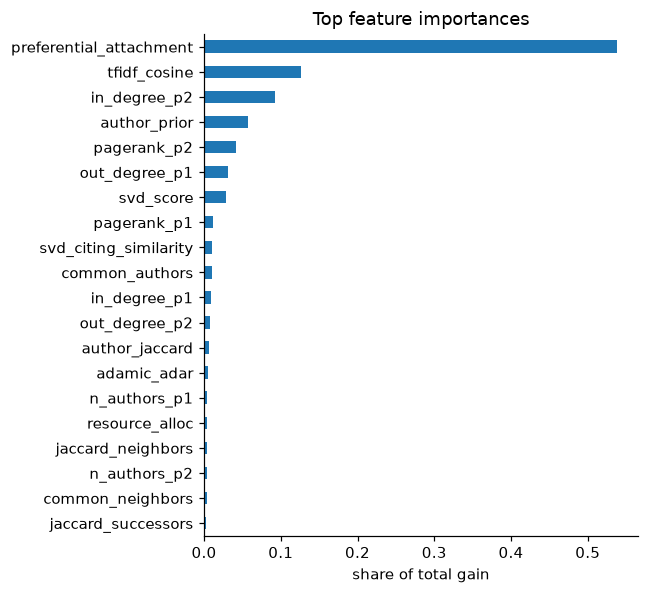

In [14]:
final = evaluate_subset(ts_all, X_test, dev.test_labels, all_features, params=dict(learning_rate=0.03, n_estimators=3000), log=lambda *a: None)
print({k: round(v, 4) for k, v in final["test"].items()})
imp = final["importance"]["share"].sort_values()
fig, ax = plt.subplots(figsize=(6, 5.5))
imp.tail(20).plot.barh(ax=ax); ax.set_xlabel("share of total gain"); ax.set_title("Top feature importances"); plt.tight_layout(); plt.show()

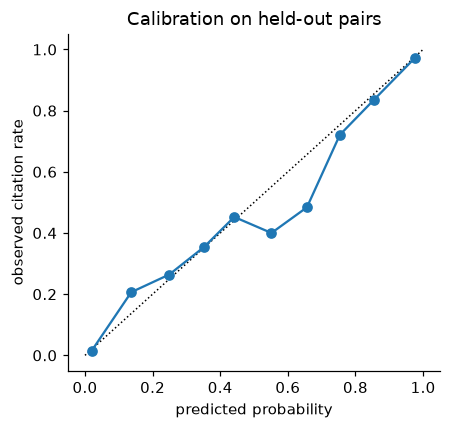

,bin,n,mean_predicted,observed_rate
0,0.0-0.1,798,0.020,0.015
1,0.1-0.2,92,0.137,0.207
2,0.2-0.3,53,0.249,0.264
3,0.3-0.4,48,0.352,0.354
4,0.4-0.5,42,0.441,0.452
5,0.5-0.6,40,0.552,0.400
6,0.6-0.7,31,0.656,0.484
7,0.7-0.8,43,0.754,0.721
8,0.8-0.9,103,0.854,0.835
9,0.9-1.0,838,0.976,0.973


In [15]:
cal = final["calibration"]
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.plot(cal.mean_predicted, cal.observed_rate, "o-")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed citation rate"); ax.set_title("Calibration on held-out pairs"); plt.tight_layout(); plt.show()
cal.round(3)

In [16]:
p, y = final["test_predictions"], dev.test_labels
ll = -(y * np.log(np.clip(p, 1e-6, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-6, 1)))
od_u = X_test["out_degree_p1"].to_numpy()
rows = []
for name, mask in {"out-degree(u) = 0": od_u == 0, "1-10": (od_u >= 1) & (od_u <= 10), "11-50": (od_u > 10) & (od_u <= 50), "> 50": od_u > 50}.items():
    if mask.any():
        rows.append({"citing paper u has": name, "share of pairs": f"{mask.mean():.1%}", "positive rate": round(y[mask].mean(), 3), "mean log loss": round(ll[mask].mean(), 4)})
pd.DataFrame(rows).set_index("citing paper u has")

,share of pairs,positive rate,mean log loss
citing paper u has,,,
out-degree(u) = 0,12.7%,0.042,0.0860
1-10,47.6%,0.422,0.2105
11-50,35.8%,0.718,0.2272
> 50,3.9%,0.939,0.0978


**Reading.** Errors are concentrated where the model has the least information: papers with few or no known references. Calibration matters for a
log-loss metric, because a confident wrong answer is punished heavily; predictions are clipped to [1e-6, 1 - 1e-6] when a submission is written.

## 8. Predictions for the real test pairs
With the real challenge data, the final model is trained on the *full* graph with the same protocol and the test pairs are featurised on the full known graph.

In [17]:
if DATA_DIR and ds.test_labels is None:
    ts_full = build_training_set(ds, FeatureBuilder(ds, E_emb, svd_dim=32), groups, n_folds=5, seed=SEED, leak=False, log=lambda *a: None)
    b_full = FeatureBuilder(ds, E_emb, svd_dim=32)
    Xt = b_full.build(ds.edges, ds.test_pairs, groups)
    res = evaluate_subset(ts_full, Xt, None, all_features, params=dict(learning_rate=0.03, n_estimators=3000), log=lambda *a: None)
    write_submission("submission.csv", res["test_predictions"], DATA_DIR / "submission_random.csv")
    print("cross-validated log loss of the final model:", round(res["cv"]["logloss"], 4), "- submission.csv written")
else:
    print("synthetic / pseudo-test run: nothing to submit (the held-out pairs above are the evaluation).")

synthetic / pseudo-test run: nothing to submit (the held-out pairs above are the evaluation).


## 9. Summary and limits
* The cross-validation score is only trustworthy if graph features never see the pair's own edge. This notebook enforces that and *measures* the consequence.
* Feature groups, in the order they help, are shown in section 6; the real-data numbers are in the repository documentation.
* **Limits.** Hidden-edge sampling assumes the real test set was built the same way (the checks in section 2 support it, they cannot prove it);
  negatives are uniform random pairs, so hard negatives (similar papers that do not cite each other) are not covered; author names are matched as
  written; SBERT embeddings use the first 128 word-pieces of each abstract; the id-order features that happen to exist in the real data are deliberately not used.